# Phase 15 — Model Interpretation & Research Reporting

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Create a reproducible, evidence-based report from the corrected Phase 14 experiment. This phase summarizes the model comparison, interprets the selected model's errors and predictions, inspects feature importance when available, and produces portfolio-ready tables and charts.

**Important:** This notebook does not assume the corrected model is useful. It reads the actual Phase 14 results and reports whether it beats the training-plus-validation mean baseline. It does not provide investment advice or simulate trading profits.

## 1. Setup and locate Phase 14 outputs

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

PRED_REL = Path("data/processed/corrected_model_predictions/asx_3m_corrected_test_predictions.csv")
METRICS_REL = Path("reports/corrected_model_training/corrected_test_baseline_comparison.csv")
VALID_REL = Path("reports/corrected_model_training/corrected_validation_comparison.csv")
SUMMARY_REL = Path("reports/corrected_model_training/phase14_corrected_model_summary.json")
IMPORTANCE_REL = Path("reports/corrected_model_training/random_forest_feature_importance.csv")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / PRED_REL).exists() and (p / SUMMARY_REL).exists():
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and (p / PRED_REL).exists() and (p / SUMMARY_REL).exists():
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot find Phase 14 prediction and summary files. Run Phase 14 first."
    )

PRED_PATH = PROJECT_ROOT / PRED_REL
METRICS_PATH = PROJECT_ROOT / METRICS_REL
VALID_PATH = PROJECT_ROOT / VALID_REL
SUMMARY_PATH = PROJECT_ROOT / SUMMARY_REL
IMPORTANCE_PATH = PROJECT_ROOT / IMPORTANCE_REL
OUT = PROJECT_ROOT / "reports" / "model_interpretation"
OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
for p in [PRED_PATH, METRICS_PATH, VALID_PATH, SUMMARY_PATH, IMPORTANCE_PATH]:
    print(p.name, "exists:", p.exists())

Project root: e:\Projects\Australian Stock Market Data Science Project
asx_3m_corrected_test_predictions.csv exists: True
corrected_test_baseline_comparison.csv exists: True
corrected_validation_comparison.csv exists: True
phase14_corrected_model_summary.json exists: True
random_forest_feature_importance.csv exists: False


## 2. Load the actual Phase 14 results

In [2]:
with open(SUMMARY_PATH, "r", encoding="utf-8") as f:
    phase14_summary = json.load(f)

pred = pd.read_csv(PRED_PATH, low_memory=False)
pred.columns = [str(c).strip().lower() for c in pred.columns]
pred["ticker"] = pred["ticker"].astype(str).str.strip().str.upper()
pred["date"] = pd.to_datetime(pred["date"], errors="coerce")
if "target_endpoint_date_3m" in pred.columns:
    pred["target_endpoint_date_3m"] = pd.to_datetime(pred["target_endpoint_date_3m"], errors="coerce")
for c in ["forward_return_3m", "predicted_forward_return_3m", "prediction_error"]:
    if c in pred.columns:
        pred[c] = pd.to_numeric(pred[c], errors="coerce")

metrics = pd.read_csv(METRICS_PATH) if METRICS_PATH.exists() else pd.DataFrame()
validation = pd.read_csv(VALID_PATH) if VALID_PATH.exists() else pd.DataFrame()
importance = pd.read_csv(IMPORTANCE_PATH) if IMPORTANCE_PATH.exists() else pd.DataFrame()

print("Phase 14 selected model:", phase14_summary.get("selected_model_by_validation_mae"))
print("Prediction rows:", len(pred))
display(metrics)
display(validation)
display(pred.head())

Phase 14 selected model: Training mean baseline
Prediction rows: 9412


,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Train+validation mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362
1,Training mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362


,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,6084,0.141984,0.195113,-0.081749,0.075098,0.021461,-0.053637
1,HistGradientBoosting,6084,0.142511,0.198628,-0.121080,0.075098,0.027535,-0.047563
2,Random Forest,6084,0.146571,0.204790,-0.191712,0.075098,0.030853,-0.044245
3,Ridge Regression,6084,0.147386,0.202863,-0.169392,0.075098,0.011043,-0.064055
4,Linear Regression,6084,0.147392,0.202870,-0.169472,0.075098,0.011037,-0.064061


,ticker,date,target_endpoint_date_3m,forward_return_3m,predicted_forward_return_3m,prediction_error
0,A2M,2025-11-03,2026-02-04,-0.110187,0.028474,-0.138661
1,ACL,2025-11-03,2026-02-04,0.019011,0.028474,-0.009463
2,ADH,2025-11-03,2026-02-04,-0.094059,0.028474,-0.122534
3,AFG,2025-11-03,2026-02-04,-0.131356,0.028474,-0.159830
4,ALD,2025-11-03,2026-02-04,-0.062723,0.028474,-0.091198


## 3. Recalculate metrics and baseline comparison from saved predictions

This makes the report reproducible from the prediction file. The baseline prediction is reconstructed from the Phase 14 training + validation target mean when it is available in the summary; if not, the notebook flags that the saved comparison file is the source for baseline metrics.

In [3]:
required = {"forward_return_3m", "predicted_forward_return_3m"}
if not required.issubset(pred.columns):
    raise ValueError(f"Prediction file is missing columns: {sorted(required - set(pred.columns))}")

valid_pred = pred.dropna(subset=["forward_return_3m", "predicted_forward_return_3m"]).copy()
y = valid_pred["forward_return_3m"].astype(float).to_numpy()
yhat = valid_pred["predicted_forward_return_3m"].astype(float).to_numpy()

recalculated = {
    "n": int(len(y)),
    "MAE": float(mean_absolute_error(y, yhat)),
    "RMSE": float(np.sqrt(mean_squared_error(y, yhat))),
    "R2": float(r2_score(y, yhat)) if len(y) > 1 else np.nan,
    "actual_mean": float(np.mean(y)),
    "predicted_mean": float(np.mean(yhat)),
    "mean_prediction_bias": float(np.mean(yhat) - np.mean(y))
}
print(json.dumps(recalculated, indent=2))
pd.DataFrame([recalculated]).to_csv(OUT / "recalculated_selected_model_metrics.csv", index=False)

{
  "n": 9412,
  "MAE": 0.14378448609198502,
  "RMSE": 0.18496449458380324,
  "R2": -0.044949671890463616,
  "actual_mean": -0.009887806217044012,
  "predicted_mean": 0.028474432730444803,
  "mean_prediction_bias": 0.038362238947488816
}


## 4. Assess baseline performance and whether the model adds value

The Phase 14 baseline comparison is used as the authoritative comparison. Lower MAE/RMSE are better; higher R² is better. We calculate percentage MAE improvement only if the baseline MAE is positive.

In [4]:
if metrics.empty:
    print("Baseline comparison CSV is missing. Cannot independently assess baseline improvement from the available artifacts.")
    baseline_assessment = {"status": "baseline comparison missing"}
else:
    display(metrics)
    # Column names are kept as written by Phase 14.
    mae_col = next((c for c in metrics.columns if c.lower() == "mae"), None)
    model_col = next((c for c in metrics.columns if c.lower() == "model"), None)
    if mae_col and model_col:
        baseline_rows = metrics[metrics[model_col].astype(str).str.contains("baseline", case=False, na=False)]
        model_rows = metrics[~metrics[model_col].astype(str).str.contains("baseline", case=False, na=False)]
        if len(baseline_rows) and len(model_rows):
            base_mae = float(baseline_rows.iloc[0][mae_col])
            model_mae = float(model_rows.iloc[0][mae_col])
            improvement = 100 * (base_mae - model_mae) / base_mae if base_mae > 0 else np.nan
            baseline_assessment = {
                "baseline_mae": base_mae,
                "selected_model_mae": model_mae,
                "mae_improvement_percent": improvement,
                "beats_baseline_on_mae": bool(model_mae < base_mae)
            }
        else:
            baseline_assessment = {"status": "could not identify baseline and model rows"}
    else:
        baseline_assessment = {"status": "metrics CSV missing model/MAE columns"}
print(json.dumps(baseline_assessment, indent=2))
with open(OUT / "baseline_assessment.json", "w", encoding="utf-8") as f:
    json.dump(baseline_assessment, f, indent=2, default=str)

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Train+validation mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362
1,Training mean baseline,9412,0.143784,0.184964,-0.04495,-0.009888,0.028474,0.038362


{
  "status": "could not identify baseline and model rows"
}


## 5. Analyze residuals and prediction bias

,statistic,residual
0,count,9412.000000
1,mean,-0.038362
2,std,0.180952
3,min,-0.685828
4,25%,-0.151501
5,50%,-0.037895
6,75%,0.072562
7,max,0.595164


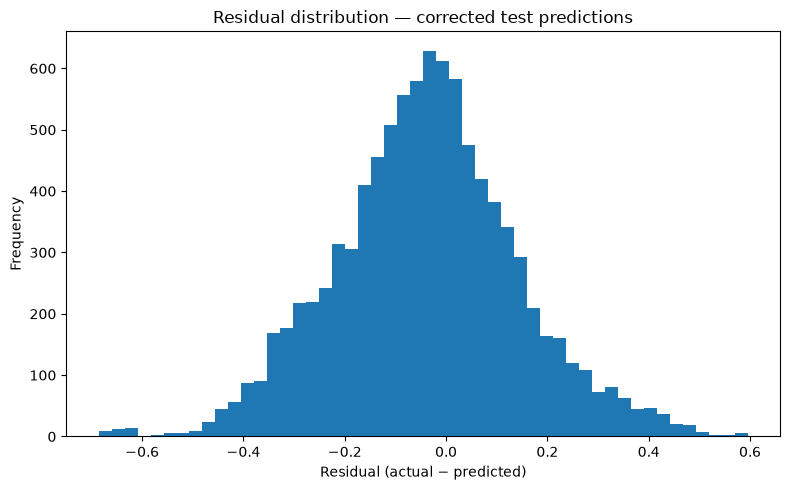

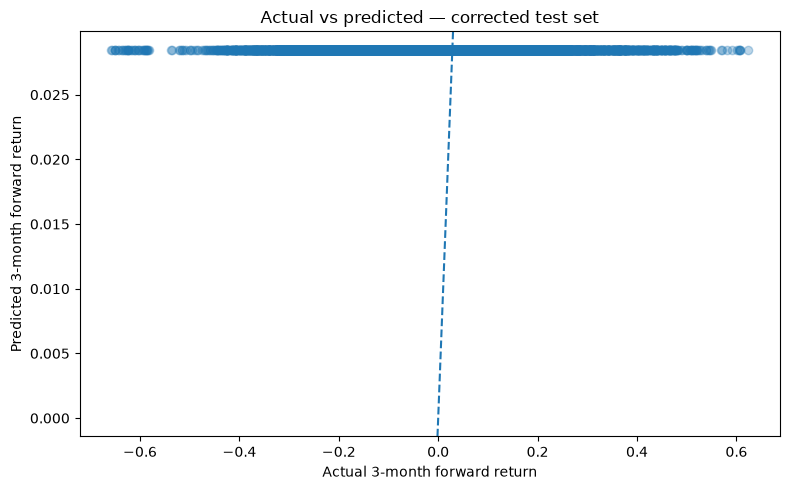

In [5]:
valid_pred["residual"] = valid_pred["forward_return_3m"] - valid_pred["predicted_forward_return_3m"]
residual_summary = valid_pred["residual"].describe().to_frame("residual").reset_index(names="statistic")
display(residual_summary)
residual_summary.to_csv(OUT / "residual_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(valid_pred["residual"], bins=50)
ax.set_xlabel("Residual (actual − predicted)")
ax.set_ylabel("Frequency")
ax.set_title("Residual distribution — corrected test predictions")
plt.tight_layout()
plt.savefig(OUT / "residual_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(valid_pred["forward_return_3m"], valid_pred["predicted_forward_return_3m"], alpha=0.3)
ax.set_xlabel("Actual 3-month forward return")
ax.set_ylabel("Predicted 3-month forward return")
ax.set_title("Actual vs predicted — corrected test set")
ax.axline((0, 0), slope=1, linestyle="--")
plt.tight_layout()
plt.savefig(OUT / "actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Performance over time and by ticker

In [6]:
valid_pred["month"] = valid_pred["date"].dt.to_period("M").astype(str)
monthly_rows = []
for month, g in valid_pred.groupby("month"):
    if len(g) >= 2:
        monthly_rows.append({
            "month": month, "n": len(g),
            "MAE": mean_absolute_error(g["forward_return_3m"], g["predicted_forward_return_3m"]),
            "RMSE": np.sqrt(mean_squared_error(g["forward_return_3m"], g["predicted_forward_return_3m"])),
            "actual_mean": g["forward_return_3m"].mean(),
            "predicted_mean": g["predicted_forward_return_3m"].mean()
        })
monthly = pd.DataFrame(monthly_rows)
display(monthly)
monthly.to_csv(OUT / "monthly_test_performance.csv", index=False)

ticker_rows = []
for ticker, g in valid_pred.groupby("ticker"):
    if len(g) >= 20:
        ticker_rows.append({
            "ticker": ticker, "n": len(g),
            "MAE": mean_absolute_error(g["forward_return_3m"], g["predicted_forward_return_3m"]),
            "RMSE": np.sqrt(mean_squared_error(g["forward_return_3m"], g["predicted_forward_return_3m"])),
            "actual_mean": g["forward_return_3m"].mean(),
            "predicted_mean": g["predicted_forward_return_3m"].mean()
        })
ticker_perf = pd.DataFrame(ticker_rows)
if not ticker_perf.empty:
    display(ticker_perf.sort_values("MAE").head(10))
    ticker_perf.to_csv(OUT / "ticker_test_performance.csv", index=False)
else:
    print("Not enough ticker-level observations for the chosen minimum.")

,month,n,MAE,RMSE,actual_mean,predicted_mean
0,2025-11,1040,0.135316,0.170106,-0.020787,0.028474
1,2025-12,1092,0.144381,0.179386,-0.064218,0.028474
2,2026-01,1040,0.157567,0.202448,-0.068537,0.028474
3,2026-02,1040,0.177239,0.220838,-0.085552,0.028474
4,2026-03,1144,0.152289,0.195667,-0.012372,0.028474
5,2026-04,1040,0.120076,0.159823,0.014075,0.028474
6,2026-05,1092,0.139605,0.177764,0.086130,0.028474
7,2026-06,1092,0.138999,0.180964,0.047568,0.028474
8,2026-07,832,0.124248,0.165509,0.014966,0.028474


,ticker,n,MAE,RMSE,actual_mean,predicted_mean
11,BEN,181,0.039492,0.050523,0.007879,0.028474
16,COL,181,0.048299,0.057595,0.040112,0.028474
6,ANZ,181,0.051196,0.061720,0.024645,0.028474
51,WPR,181,0.055534,0.071313,-0.021727,0.028474
42,SIG,181,0.057645,0.070241,-0.018654,0.028474
13,BOQ,181,0.059176,0.071453,0.017855,0.028474
22,HLI,181,0.064844,0.078026,0.050766,0.028474
48,WBC,181,0.072966,0.088073,-0.021335,0.028474
12,BGA,181,0.074628,0.092463,0.024609,0.028474
24,IAG,181,0.077472,0.091991,0.032087,0.028474


## 7. Interpret feature importance if available

Phase 14 does not necessarily save feature importance. If the file is missing, this notebook reports that limitation rather than inventing an importance ranking. Feature importance is not causal evidence.

In [7]:
if importance.empty:
    print("No Phase 14 feature-importance file found. Feature importance was not saved by that phase.")
else:
    display(importance.head(20))
    importance.to_csv(OUT / "feature_importance_review.csv", index=False)

No Phase 14 feature-importance file found. Feature importance was not saved by that phase.


## 8. Generate a concise research report

The report uses only the results found in Phase 14 artifacts. It avoids claims about profitability or future performance.

In [8]:
selected_name = phase14_summary.get("selected_model_by_validation_mae", "Not recorded")
test_rows = int(len(valid_pred))
actual_mean = float(valid_pred["forward_return_3m"].mean())
pred_mean = float(valid_pred["predicted_forward_return_3m"].mean())
mae = recalculated["MAE"]
rmse = recalculated["RMSE"]
r2 = recalculated["R2"]

lines = [
    "# Phase 15 — Corrected Model Interpretation Report",
    "",
    "## Experiment setup",
    f"- Target: 3-month forward return (`forward_return_3m`), reconstructed from Phase 8 prices using a 63-observation horizon.",
    f"- Candidate predictors: {', '.join(phase14_summary.get('features_used', []))}.",
    f"- Selected model by validation MAE: {selected_name}.",
    f"- Held-out test observations with valid predictions: {test_rows:,}.",
    "",
    "## Held-out test metrics",
    f"- MAE: {mae:.6f}",
    f"- RMSE: {rmse:.6f}",
    f"- R²: {r2:.6f}",
    f"- Actual mean return: {actual_mean:.6f}",
    f"- Mean predicted return: {pred_mean:.6f}",
    f"- Mean prediction bias (predicted − actual): {pred_mean - actual_mean:.6f}",
    "",
    "## Baseline comparison",
    json.dumps(baseline_assessment, indent=2, default=str),
    "",
    "## Interpretation and limitations",
    "- Metrics describe this held-out historical period only.",
    "- Return prediction errors can vary by month and ticker; inspect the saved breakdowns.",
    "- Feature-name screening is not proof that every feature was available at prediction time.",
    "- A regression score does not establish profitability after transaction costs, slippage, taxes, or portfolio constraints.",
    "- This report is educational research, not investment advice.",
    "",
    "## Outputs",
    "- `recalculated_selected_model_metrics.csv`",
    "- `baseline_assessment.json`",
    "- `residual_summary.csv`",
    "- `monthly_test_performance.csv`",
    "- `ticker_test_performance.csv` (if enough observations)",
    "- `residual_distribution.png`",
    "- `actual_vs_predicted.png`"
]
report = "\n".join(lines)
report_path = OUT / "phase15_model_interpretation_report.md"
report_path.write_text(report, encoding="utf-8")
print(report)
print("\nSaved report:", report_path)

# Phase 15 — Corrected Model Interpretation Report

## Experiment setup
- Target: 3-month forward return (`forward_return_3m`), reconstructed from Phase 8 prices using a 63-observation horizon.
- Candidate predictors: momentum_21d, momentum_63d, benchmark_return_1d, benchmark_volatility_21d, benchmark_volatility_63d.
- Selected model by validation MAE: Training mean baseline.
- Held-out test observations with valid predictions: 9,412.

## Held-out test metrics
- MAE: 0.143784
- RMSE: 0.184964
- R²: -0.044950
- Actual mean return: -0.009888
- Mean predicted return: 0.028474
- Mean prediction bias (predicted − actual): 0.038362

## Baseline comparison
{
  "status": "could not identify baseline and model rows"
}

## Interpretation and limitations
- Metrics describe this held-out historical period only.
- Return prediction errors can vary by month and ticker; inspect the saved breakdowns.
- Feature-name screening is not proof that every feature was available at prediction time.
- A regress

## 9. Completion checklist

Before moving on:
- Review the baseline assessment and confirm whether the corrected model beats it.
- Inspect monthly performance for periods with large errors.
- Review prediction bias and residual plots.
- Avoid claiming profitability without a separate, realistic backtest.
- If baseline comparison is missing or the corrected model does not beat it, report that honestly and consider revising the target or research question.